V8.1 configuration loaded
Config(timestep_hours=1.0, years=5, n_arms=9, arm_length_m=0.55, gearbox_ratio=20.0, battery_nominal_Wh=640.0, initial_soc=1.0, reserve_soc=0.1, normal_soc=0.35, low_soc=0.2, critical_soc=0.15, emergency_soc=0.1, max_charge_W=320.0, max_discharge_W=320.0, controller_efficiency=0.95, solar_rated_W=100.0, solar_reference_irradiance=1000.0, battery_deg_per_year=0.04, solar_deg_per_year=0.02, wec_deg_per_year=0.015, generator_deg_per_year=0.01, storm_Hs_m=3.0)

Load profile:
NORMAL    : 21.90 W
LOW       : 11.90 W
CRITICAL  : 2.20 W
EMERGENCY : 2.20 W
RESERVE   : 1.50 W

Generating DEMO environmental dataset...
            Timestamp      Hs_m      Tp_s  Solar_Irradiance_Wm2
0 2027-01-01 00:00:00  0.945802  8.038504                   0.0
1 2027-01-01 01:00:00  0.542391  6.183205                   0.0
2 2027-01-01 02:00:00  1.079522  6.627755                   0.0
3 2027-01-01 03:00:00  1.136556  7.097538                   0.0
4 2027-01-01 04:00:00  0.269076  6.1625

,Year,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Curtailed_kWh,Unmet_kWh,Minimum_SOC_%,Average_SOC_%,Final_SOC_%,Storm_h,Reserve_h,Low_h,Critical_h,Emergency_h,Normal_h
0,1,510.571,663.767,1174.337,875.5,299.282,0.0,17.699,71.22,30.579,0,0,7961,242,0,35627


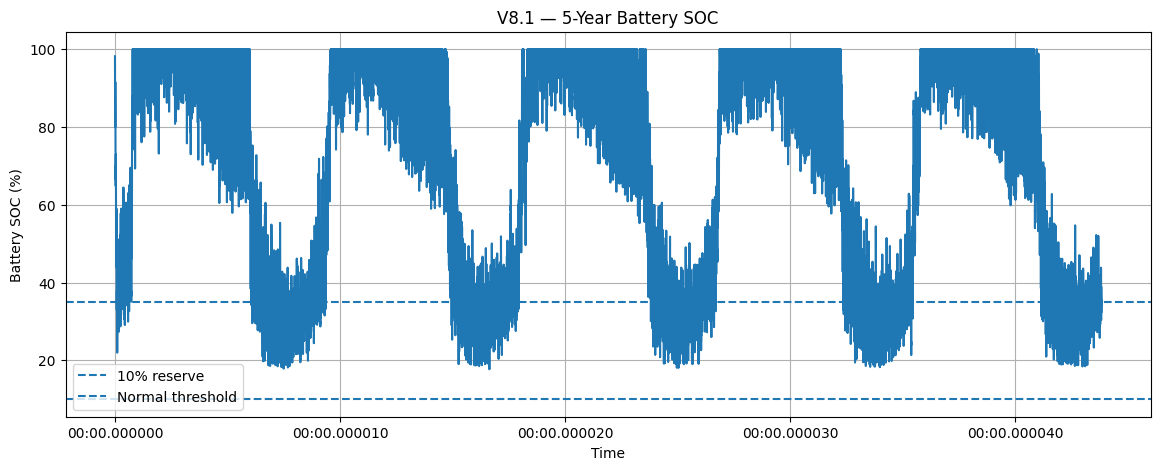

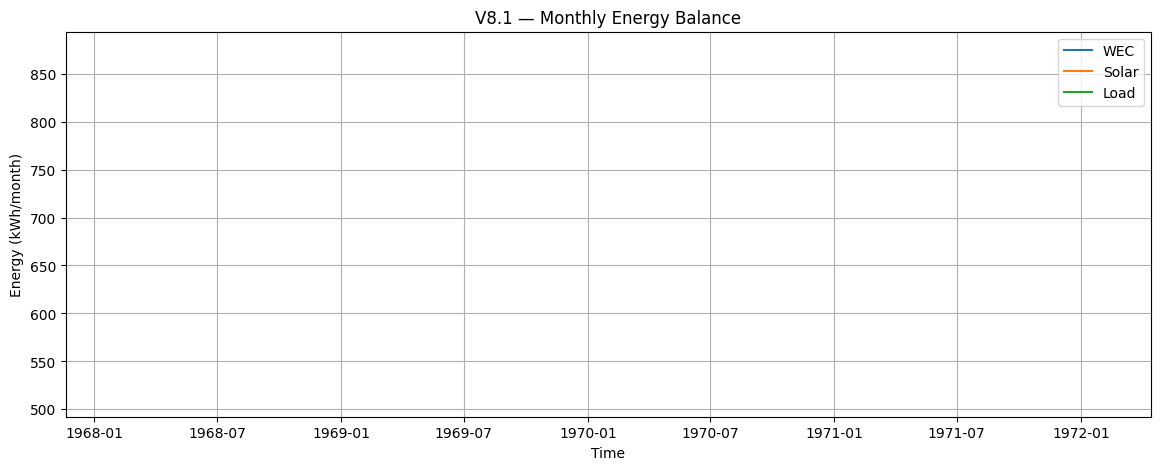

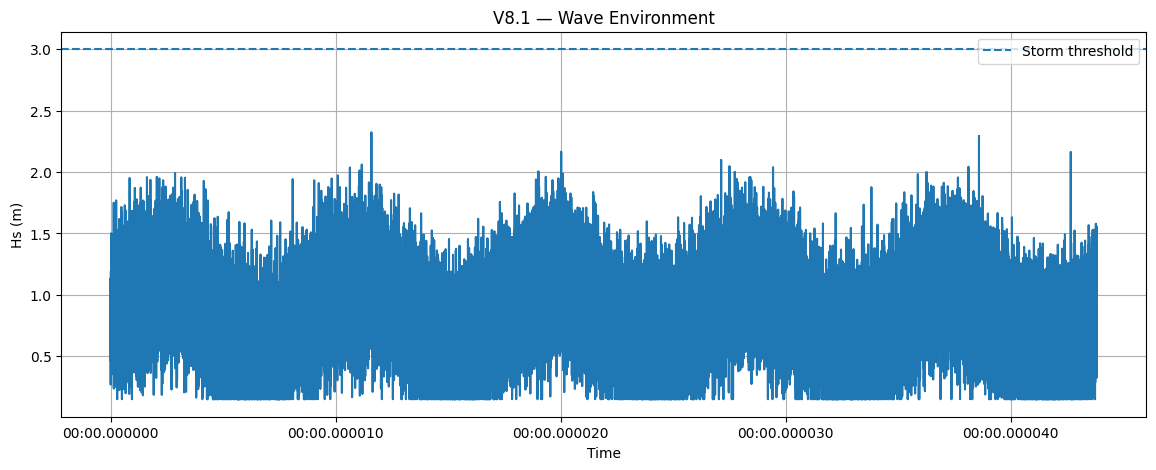


Results exported to: /content/V8_1_outputs


In [1]:
# ============================================================
# SIH SMART BUOY — V8.1
# REAL-ENVIRONMENT 5-YEAR RELIABILITY ENGINE
# ============================================================
#
# Purpose:
#   Real wave + solar time-series
#   + V7.5 calibrated WEC
#   + 640 Wh battery
#   + 9-arm WEC
#   + 10% protected SOC reserve
#   + power-management hierarchy
#   + degradation
#   + 5-year reliability analysis
#
# IMPORTANT:
#   Until real V7.5 prototype measurements are available,
#   the calibration tables below are clearly marked PROVISIONAL.
#
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from pathlib import Path

# ------------------------------------------------------------
# 1. GLOBAL CONFIGURATION
# ------------------------------------------------------------

@dataclass
class Config:

    # Simulation
    timestep_hours: float = 1.0
    years: int = 5

    # WEC architecture
    n_arms: int = 9
    arm_length_m: float = 0.55
    gearbox_ratio: float = 20.0

    # Battery
    battery_nominal_Wh: float = 640.0
    initial_soc: float = 1.00

    # Protected reserve
    reserve_soc: float = 0.10

    # SOC mode boundaries
    normal_soc: float = 0.35
    low_soc: float = 0.20
    critical_soc: float = 0.15
    emergency_soc: float = 0.10

    # Battery power limits
    max_charge_W: float = 320.0
    max_discharge_W: float = 320.0

    # Controller efficiency
    controller_efficiency: float = 0.95

    # Solar
    solar_rated_W: float = 100.0
    solar_reference_irradiance: float = 1000.0

    # Degradation assumptions
    battery_deg_per_year: float = 0.04
    solar_deg_per_year: float = 0.02
    wec_deg_per_year: float = 0.015
    generator_deg_per_year: float = 0.01

    # Environmental protection
    # This is NOT a structural validation limit.
    # Replace with experimentally established value.
    storm_Hs_m: float = 3.0


CFG = Config()

print("V8.1 configuration loaded")
print(CFG)


# ============================================================
# 2. PROVISIONAL V7.5 CALIBRATION TABLES
# ============================================================
#
# REPLACE THESE WITH ACTUAL EXPERIMENTAL V7.5 RESULTS.
#
# Torque: provisional relationship derived from V6/V7 work.
# Arm RPM: provisional relationship.
#
# These are placeholders ONLY.
# ============================================================

TORQUE_TABLE = pd.DataFrame({
    "Hs_m": [0.25, 0.50, 1.00, 1.50, 2.00, 2.50, 3.00],
    "Torque_Nm": [0.30, 1.20, 4.80, 10.80, 19.20, 30.00, 43.20]
})

RPM_TABLE = pd.DataFrame({
    "Hs_m": [0.25, 0.50, 1.00, 1.50, 2.00, 2.50, 3.00],
    "Arm_RPM": [1.82, 3.43, 6.36, 8.75, 11.53, 13.90, 16.14]
})

# Generator efficiency map
GEN_EFF_TABLE = pd.DataFrame({
    "RPM": [0, 30, 50, 75, 100, 125, 150,
            175, 200, 250, 300, 400, 500, 600],
    "Efficiency": [0.00, 0.02, 0.08, 0.22, 0.38, 0.50,
                   0.55, 0.58, 0.60, 0.63, 0.65,
                   0.62, 0.55, 0.45]
})

# Gearbox efficiency map
GEAR_EFF_TABLE = pd.DataFrame({
    "RPM": [0, 50, 100, 150, 200, 300, 400, 500, 600],
    "Efficiency": [0.00, 0.88, 0.90, 0.90, 0.90,
                   0.90, 0.89, 0.88, 0.86]
})


# ============================================================
# 3. LOAD PROFILE
# ============================================================

# Normal mode
NORMAL_LOAD = {
    "MCU": 1.5,
    "PowerManagement": 0.8,
    "DataLogger": 0.5,
    "Temperature": 0.2,
    "WaveSensor": 1.8,
    "GNSS": 1.5,
    "Communication": 15.0,
    "Status": 0.1,
    "NonEssential": 0.5
}

LOW_LOAD = {
    "MCU": 1.2,
    "PowerManagement": 0.7,
    "DataLogger": 0.4,
    "Temperature": 0.2,
    "WaveSensor": 0.6,
    "GNSS": 0.8,
    "Communication": 8.0,
    "Status": 0.0,
    "NonEssential": 0.0
}

CRITICAL_LOAD = {
    "MCU": 1.0,
    "PowerManagement": 0.7,
    "DataLogger": 0.3,
    "Temperature": 0.2,
    "WaveSensor": 0.0,
    "GNSS": 0.0,
    "Communication": 0.0,
    "Status": 0.0,
    "NonEssential": 0.0
}

EMERGENCY_LOAD = {
    "MCU": 1.0,
    "PowerManagement": 0.7,
    "DataLogger": 0.3,
    "Temperature": 0.2,
    "WaveSensor": 0.0,
    "GNSS": 0.0,
    "Communication": 0.0,
    "Status": 0.0,
    "NonEssential": 0.0
}

RESERVE_LOAD = {
    "MCU": 0.8,
    "PowerManagement": 0.5,
    "DataLogger": 0.0,
    "Temperature": 0.2,
    "WaveSensor": 0.0,
    "GNSS": 0.0,
    "Communication": 0.0,
    "Status": 0.0,
    "NonEssential": 0.0
}


def load_power(load_dict):
    return sum(load_dict.values())


LOADS = {
    "NORMAL": load_power(NORMAL_LOAD),
    "LOW": load_power(LOW_LOAD),
    "CRITICAL": load_power(CRITICAL_LOAD),
    "EMERGENCY": load_power(EMERGENCY_LOAD),
    "RESERVE": load_power(RESERVE_LOAD)
}

print("\nLoad profile:")
for mode, power in LOADS.items():
    print(f"{mode:10s}: {power:.2f} W")


# ============================================================
# 4. ENVIRONMENT LOADER
# ============================================================

def generate_demo_environment(years=5):
    """
    DEMO ONLY.

    Generates synthetic environmental data so the V8.1 engine
    can be tested before real environmental CSV files exist.

    Replace with load_environment_csv() when real data is ready.
    """

    hours = int(years * 365.25 * 24)

    timestamps = pd.date_range(
        "2027-01-01",
        periods=hours,
        freq="h"
    )

    rng = np.random.default_rng(42)

    # Seasonal wave baseline
    day_of_year = timestamps.dayofyear.values

    seasonal_wave = (
        1.0
        + 0.30 * np.sin(
            2 * np.pi * day_of_year / 365.25
        )
    )

    Hs = np.clip(
        0.85 * seasonal_wave
        + rng.normal(0, 0.30, hours),
        0.15,
        3.2
    )

    Tp = np.clip(
        7.0
        + 1.2 * np.sin(
            2 * np.pi * day_of_year / 365.25
        )
        + rng.normal(0, 0.8, hours),
        3.0,
        12.0
    )

    # Simple day/night solar model
    hour = timestamps.hour.values

    solar_factor = np.maximum(
        0,
        np.sin(
            np.pi * (hour - 6) / 12
        )
    )

    # Seasonal solar availability
    seasonal_solar = np.clip(
        0.65
        + 0.35 * np.sin(
            2 * np.pi * (day_of_year - 80) / 365.25
        ),
        0.05,
        1.0
    )

    cloud_factor = np.clip(
        rng.normal(0.75, 0.20, hours),
        0,
        1
    )

    irradiance = (
        1000
        * solar_factor
        * seasonal_solar
        * cloud_factor
    )

    return pd.DataFrame({
        "Timestamp": timestamps,
        "Hs_m": Hs,
        "Tp_s": Tp,
        "Solar_Irradiance_Wm2": irradiance
    })


def load_environment_csv(filepath):
    """
    Expected columns:

    Timestamp
    Hs_m
    Tp_s
    Solar_Irradiance_Wm2
    """

    df = pd.read_csv(filepath)

    required = [
        "Timestamp",
        "Hs_m",
        "Tp_s",
        "Solar_Irradiance_Wm2"
    ]

    missing = [c for c in required if c not in df.columns]

    if missing:
        raise ValueError(
            f"Missing required columns: {missing}"
        )

    df["Timestamp"] = pd.to_datetime(
        df["Timestamp"]
    )

    df = df.sort_values("Timestamp")
    df = df.drop_duplicates("Timestamp")

    df = df.set_index("Timestamp")

    return df


# ============================================================
# 5. CALIBRATION INTERPOLATORS
# ============================================================

def interpolate_1d(x, xp, fp):

    return np.interp(
        x,
        xp,
        fp,
        left=fp[0],
        right=fp[-1]
    )


def torque_from_wave(Hs):

    return interpolate_1d(
        Hs,
        TORQUE_TABLE["Hs_m"].values,
        TORQUE_TABLE["Torque_Nm"].values
    )


def arm_rpm_from_wave(Hs):

    return interpolate_1d(
        Hs,
        RPM_TABLE["Hs_m"].values,
        RPM_TABLE["Arm_RPM"].values
    )


def generator_efficiency(rpm):

    return interpolate_1d(
        rpm,
        GEN_EFF_TABLE["RPM"].values,
        GEN_EFF_TABLE["Efficiency"].values
    )


def gearbox_efficiency(rpm):

    return interpolate_1d(
        rpm,
        GEAR_EFF_TABLE["RPM"].values,
        GEAR_EFF_TABLE["Efficiency"].values
    )


# ============================================================
# 6. DEGRADATION
# ============================================================

def degradation_factor(rate_per_year, year_fraction):

    return (1 - rate_per_year) ** year_fraction


def battery_capacity_Wh(year_fraction):

    return (
        CFG.battery_nominal_Wh
        * degradation_factor(
            CFG.battery_deg_per_year,
            year_fraction
        )
    )


def solar_degradation(year_fraction):

    return degradation_factor(
        CFG.solar_deg_per_year,
        year_fraction
    )


def wec_degradation(year_fraction):

    return degradation_factor(
        CFG.wec_deg_per_year,
        year_fraction
    )


def generator_degradation(year_fraction):

    return degradation_factor(
        CFG.generator_deg_per_year,
        year_fraction
    )


# ============================================================
# 7. SOLAR MODEL
# ============================================================

def solar_power(
    irradiance,
    year_fraction
):

    degradation = solar_degradation(
        year_fraction
    )

    power = (
        CFG.solar_rated_W
        * irradiance
        / CFG.solar_reference_irradiance
        * degradation
    )

    return max(0.0, power)


# ============================================================
# 8. WEC MODEL
# ============================================================

def wec_power_single_arm(
    Hs,
    Tp,
    year_fraction
):

    # Storm protection
    if Hs >= CFG.storm_Hs_m:
        return 0.0, 0.0, 0.0, 0.0

    torque = torque_from_wave(Hs)

    arm_rpm = arm_rpm_from_wave(Hs)

    omega = (
        2
        * np.pi
        * arm_rpm
        / 60
    )

    mechanical_power = (
        torque
        * omega
    )

    generator_rpm = (
        arm_rpm
        * CFG.gearbox_ratio
    )

    eta_gear = gearbox_efficiency(
        generator_rpm
    )

    eta_generator = generator_efficiency(
        generator_rpm
    )

    degradation = (
        wec_degradation(year_fraction)
        * generator_degradation(year_fraction)
    )

    electrical_power = (
        mechanical_power
        * eta_gear
        * eta_generator
        * CFG.controller_efficiency
        * degradation
    )

    return (
        electrical_power,
        arm_rpm,
        generator_rpm,
        mechanical_power
    )


def total_wec_power(
    Hs,
    Tp,
    year_fraction
):

    single_arm = wec_power_single_arm(
        Hs,
        Tp,
        year_fraction
    )

    return single_arm[0] * CFG.n_arms


# ============================================================
# 9. POWER MANAGEMENT
# ============================================================

def determine_mode(soc):

    if soc > CFG.normal_soc:
        return "NORMAL"

    elif soc > CFG.low_soc:
        return "LOW"

    elif soc > CFG.critical_soc:
        return "CRITICAL"

    elif soc > CFG.emergency_soc:
        return "EMERGENCY"

    else:
        return "RESERVE"


# ============================================================
# 10. ONE-YEAR / MULTI-YEAR SIMULATION
# ============================================================

def run_simulation(environment):

    df = environment.copy()

    # Ensure hourly data
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)

    df = df.sort_index()

    soc = CFG.initial_soc

    results = []

    reserve_events = 0
    was_in_reserve = False

    for timestamp, row in df.iterrows():

        elapsed_hours = (
            timestamp - df.index[0]
        ).total_seconds() / 3600.0

        year_fraction = (
            elapsed_hours / (365.25 * 24)
        )

        year_number = int(
            year_fraction
        ) + 1

        year_number = min(
            year_number,
            CFG.years
        )

        Hs = float(
            row["Hs_m"]
        )

        Tp = float(
            row["Tp_s"]
        )

        irradiance = float(
            row["Solar_Irradiance_Wm2"]
        )

        # ----------------------------------------------------
        # MODE
        # ----------------------------------------------------

        mode = determine_mode(soc)

        # Reserve event detection
        if mode == "RESERVE" and not was_in_reserve:
            reserve_events += 1

        was_in_reserve = (
            mode == "RESERVE"
        )

        # ----------------------------------------------------
        # GENERATION
        # ----------------------------------------------------

        P_wec = total_wec_power(
            Hs,
            Tp,
            year_fraction
        )

        P_solar = solar_power(
            irradiance,
            year_fraction
        )

        E_wec = (
            P_wec
            * CFG.timestep_hours
        )

        E_solar = (
            P_solar
            * CFG.timestep_hours
        )

        # ----------------------------------------------------
        # LOAD
        # ----------------------------------------------------

        P_load = LOADS[mode]

        E_load = (
            P_load
            * CFG.timestep_hours
        )

        # ----------------------------------------------------
        # BATTERY
        # ----------------------------------------------------

        capacity = battery_capacity_Wh(
            year_fraction
        )

        battery_energy = (
            soc * capacity
        )

        generation = (
            E_wec + E_solar
        )

        net_energy = (
            generation - E_load
        )

        curtailed = 0.0
        unmet = 0.0

        if net_energy >= 0:

            charge_energy = min(
                net_energy,
                CFG.max_charge_W
                * CFG.timestep_hours
            )

            new_energy = (
                battery_energy
                + charge_energy
            )

            max_energy = capacity

            if new_energy > max_energy:

                curtailed = (
                    new_energy
                    - max_energy
                )

                new_energy = max_energy

            soc = (
                new_energy
                / capacity
            )

        else:

            requested = -net_energy

            max_available_energy = max(
                0.0,
                battery_energy
                - CFG.reserve_soc * capacity
            )

            discharge = min(
                requested,
                max_available_energy,
                CFG.max_discharge_W
                * CFG.timestep_hours
            )

            battery_energy -= discharge

            unmet = (
                requested
                - discharge
            )

            soc = (
                battery_energy
                / capacity
            )

            soc = max(
                CFG.reserve_soc,
                soc
            )

        # ----------------------------------------------------
        # RECORD
        # ----------------------------------------------------

        results.append({

            "Timestamp": timestamp,
            "Year": year_number,

            "Hs_m": Hs,
            "Tp_s": Tp,

            "WEC_Power_W": P_wec,
            "Solar_Power_W": P_solar,

            "WEC_Energy_Wh": E_wec,
            "Solar_Energy_Wh": E_solar,

            "Load_Power_W": P_load,
            "Load_Energy_Wh": E_load,

            "Battery_Capacity_Wh": capacity,
            "SOC": soc,

            "Curtailed_Wh": curtailed,
            "Unmet_Wh": unmet,

            "Mode": mode,

            "Storm": Hs >= CFG.storm_Hs_m
        })

    result = pd.DataFrame(results)

    result["SOC_pct"] = (
        result["SOC"] * 100
    )

    result.attrs[
        "reserve_events"
    ] = reserve_events

    return result


# ============================================================
# 11. YEARLY SUMMARY
# ============================================================

def yearly_summary(result):

    rows = []

    for year, group in result.groupby("Year"):

        rows.append({

            "Year": year,

            "WEC_kWh":
                group["WEC_Energy_Wh"].sum()
                / 1000,

            "Solar_kWh":
                group["Solar_Energy_Wh"].sum()
                / 1000,

            "Generation_kWh":
                (
                    group["WEC_Energy_Wh"].sum()
                    +
                    group["Solar_Energy_Wh"].sum()
                ) / 1000,

            "Load_kWh":
                group["Load_Energy_Wh"].sum()
                / 1000,

            "Curtailed_kWh":
                group["Curtailed_Wh"].sum()
                / 1000,

            "Unmet_kWh":
                group["Unmet_Wh"].sum()
                / 1000,

            "Minimum_SOC_%":
                group["SOC_pct"].min(),

            "Average_SOC_%":
                group["SOC_pct"].mean(),

            "Final_SOC_%":
                group["SOC_pct"].iloc[-1],

            "Storm_h":
                group["Storm"].sum(),

            "Reserve_h":
                (group["Mode"] == "RESERVE").sum(),

            "Low_h":
                (group["Mode"] == "LOW").sum(),

            "Critical_h":
                (group["Mode"] == "CRITICAL").sum(),

            "Emergency_h":
                (group["Mode"] == "EMERGENCY").sum(),

            "Normal_h":
                (group["Mode"] == "NORMAL").sum()
        })

    return pd.DataFrame(rows)


# ============================================================
# 12. RELIABILITY METRICS
# ============================================================

def reliability_summary(result):

    total_hours = len(result)

    unmet = result["Unmet_Wh"].sum()

    survival = (
        1
        -
        result["Unmet_Wh"].gt(0).sum()
        / total_hours
    ) * 100

    return {

        "Simulation_years":
            CFG.years,

        "Total_hours":
            total_hours,

        "WEC_kWh":
            result["WEC_Energy_Wh"].sum()
            / 1000,

        "Solar_kWh":
            result["Solar_Energy_Wh"].sum()
            / 1000,

        "Total_generation_kWh":
            (
                result["WEC_Energy_Wh"].sum()
                +
                result["Solar_Energy_Wh"].sum()
            ) / 1000,

        "Load_kWh":
            result["Load_Energy_Wh"].sum()
            / 1000,

        "Curtailed_kWh":
            result["Curtailed_Wh"].sum()
            / 1000,

        "Unmet_kWh":
            unmet / 1000,

        "Minimum_SOC_%":
            result["SOC_pct"].min(),

        "Average_SOC_%":
            result["SOC_pct"].mean(),

        "Final_SOC_%":
            result["SOC_pct"].iloc[-1],

        "Reserve_hours":
            (result["Mode"] == "RESERVE").sum(),

        "Low_power_hours":
            (result["Mode"] == "LOW").sum(),

        "Critical_hours":
            (result["Mode"] == "CRITICAL").sum(),

        "Emergency_hours":
            (result["Mode"] == "EMERGENCY").sum(),

        "Storm_hours":
            result["Storm"].sum(),

        "Load_survival_%":
            survival
    }


# ============================================================
# 13. PLOTS
# ============================================================

def plot_soc(result):

    plt.figure(figsize=(14, 5))

    plt.plot(
        result["Timestamp"],
        result["SOC_pct"]
    )

    plt.axhline(
        10,
        linestyle="--",
        label="10% reserve"
    )

    plt.axhline(
        35,
        linestyle="--",
        label="Normal threshold"
    )

    plt.xlabel("Time")
    plt.ylabel("Battery SOC (%)")
    plt.title("V8.1 — 5-Year Battery SOC")
    plt.legend()
    plt.grid(True)

    plt.show()


def plot_energy(result):

    monthly = (
        result
        .set_index("Timestamp")
        .resample("ME")
        .agg({
            "WEC_Energy_Wh": "sum",
            "Solar_Energy_Wh": "sum",
            "Load_Energy_Wh": "sum"
        })
    )

    monthly = monthly / 1000

    plt.figure(figsize=(14, 5))

    plt.plot(
        monthly.index,
        monthly["WEC_Energy_Wh"],
        label="WEC"
    )

    plt.plot(
        monthly.index,
        monthly["Solar_Energy_Wh"],
        label="Solar"
    )

    plt.plot(
        monthly.index,
        monthly["Load_Energy_Wh"],
        label="Load"
    )

    plt.ylabel("Energy (kWh/month)")
    plt.xlabel("Time")
    plt.title("V8.1 — Monthly Energy Balance")
    plt.legend()
    plt.grid(True)

    plt.show()


def plot_wave(result):

    plt.figure(figsize=(14, 5))

    plt.plot(
        result["Timestamp"],
        result["Hs_m"]
    )

    plt.axhline(
        CFG.storm_Hs_m,
        linestyle="--",
        label="Storm threshold"
    )

    plt.xlabel("Time")
    plt.ylabel("Hs (m)")
    plt.title("V8.1 — Wave Environment")
    plt.legend()
    plt.grid(True)

    plt.show()


# ============================================================
# 14. RUN DEMO
# ============================================================

print("\nGenerating DEMO environmental dataset...")

environment = generate_demo_environment(
    years=CFG.years
)

print(environment.head())

print(
    f"\nEnvironment contains "
    f"{len(environment):,} hourly records."
)

print("\nRunning V8.1 simulation...")

result = run_simulation(
    environment
)

print("Simulation complete.")


# ============================================================
# 15. REPORT
# ============================================================

summary = reliability_summary(
    result
)

print("\n==============================")
print("V8.1 FIVE-YEAR RESULT")
print("==============================")

for key, value in summary.items():

    if isinstance(value, float):

        print(
            f"{key:25s}: "
            f"{value:.3f}"
        )

    else:

        print(
            f"{key:25s}: "
            f"{value}"
        )


print("\n==============================")
print("YEAR-BY-YEAR")
print("==============================")

annual = yearly_summary(
    result
)

display(
    annual.round(3)
)


# ============================================================
# 16. PLOTS
# ============================================================

plot_soc(result)
plot_energy(result)
plot_wave(result)


# ============================================================
# 17. EXPORT RESULTS
# ============================================================

output_dir = Path(
    "V8_1_outputs"
)

output_dir.mkdir(
    exist_ok=True
)

result.to_csv(
    output_dir / "V8_1_hourly_results.csv",
    index=False
)

annual.to_csv(
    output_dir / "V8_1_yearly_summary.csv",
    index=False
)

pd.DataFrame(
    [summary]
).to_csv(
    output_dir / "V8_1_reliability_summary.csv",
    index=False
)

print(
    "\nResults exported to:",
    output_dir.resolve()
)

Communication event energy: 1.50 Wh/event
Normal daily communication energy: 4.50 Wh/day

Base loads:
NORMAL    : 6.90 W
LOW       : 3.90 W
CRITICAL  : 2.20 W
EMERGENCY : 2.20 W
RESERVE   : 1.50 W

RUNNING V8.1.1

V8.1.1 FIVE-YEAR RESULT
Years                    : 5
Hours                    : 43830
WEC_kWh                  : 481.158
Solar_kWh                : 631.522
Generation_kWh           : 1112.681
Load_kWh                 : 310.644
Communication_kWh        : 8.217
Curtailed_kWh            : 802.051
Unmet_kWh                : 0.000
Minimum_SOC_%            : 86.312
Average_SOC_%            : 98.876
Final_SOC_%              : 97.586
Reserve_h                : 0
Low_h                    : 0
Critical_h               : 0
Emergency_h              : 0
Storm_h                  : 0
Unmet_hours              : 0
Load_survival_%          : 100.000

YEAR-BY-YEAR


,Year,WEC_kWh,Solar_kWh,Generation_kWh,Load_kWh,Communication_kWh,Curtailed_kWh,Unmet_kWh,Min_SOC_%,Avg_SOC_%,Final_SOC_%,Reserve_h,Low_h,Critical_h,Emergency_h,Normal_h,Storm_h,Load_survival_%
0,1,99.817,130.719,230.536,62.128,1.642,168.409,0.0,87.320,98.986,100.000,0,0,0,0,8766,0,100.0
1,2,97.971,128.874,226.845,62.129,1.644,164.716,0.0,86.925,99.003,100.000,0,0,0,0,8766,0,100.0
2,3,98.889,126.438,225.327,62.129,1.644,163.198,0.0,86.455,98.921,100.000,0,0,0,0,8766,0,100.0
3,4,94.194,124.493,218.687,62.129,1.644,156.560,0.0,86.769,98.806,99.599,0,0,0,0,8766,0,100.0
4,5,90.287,120.998,211.285,62.128,1.642,149.168,0.0,86.312,98.665,97.586,0,0,0,0,8766,0,100.0



Daily energy diagnostic:


,WEC_Wh_day,Solar_Wh_day,Load_Wh_day,Communication_Wh_day,Curtailed_Wh_day,Unmet_Wh_day,Minimum_SOC_pct_day
Timestamp,,,,,,,
2027-01-01,222.949,163.759,170.1,4.5,217.704,0.0,97.914
2027-01-02,259.489,156.424,170.1,4.5,244.717,0.0,98.965
2027-01-03,212.722,201.261,170.1,4.5,257.564,0.0,97.862
2027-01-04,181.116,154.708,170.1,4.5,170.061,0.0,97.011
2027-01-05,195.357,163.839,170.1,4.5,172.388,0.0,94.908
2027-01-06,314.018,163.001,170.1,4.5,314.256,0.0,98.050
2027-01-07,246.813,175.337,170.1,4.5,243.404,0.0,96.892
2027-01-08,309.367,178.643,170.1,4.5,318.368,0.0,97.644
2027-01-09,222.860,175.523,170.1,4.5,227.825,0.0,98.298



Communication energy:
5-year total: 8.217 kWh
Expected normal-day value: 4.50 Wh/day


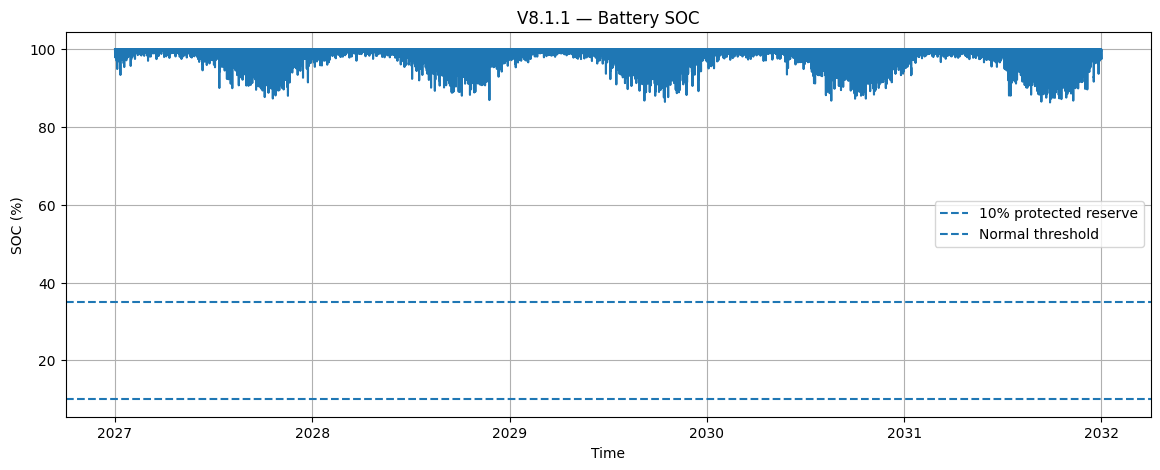

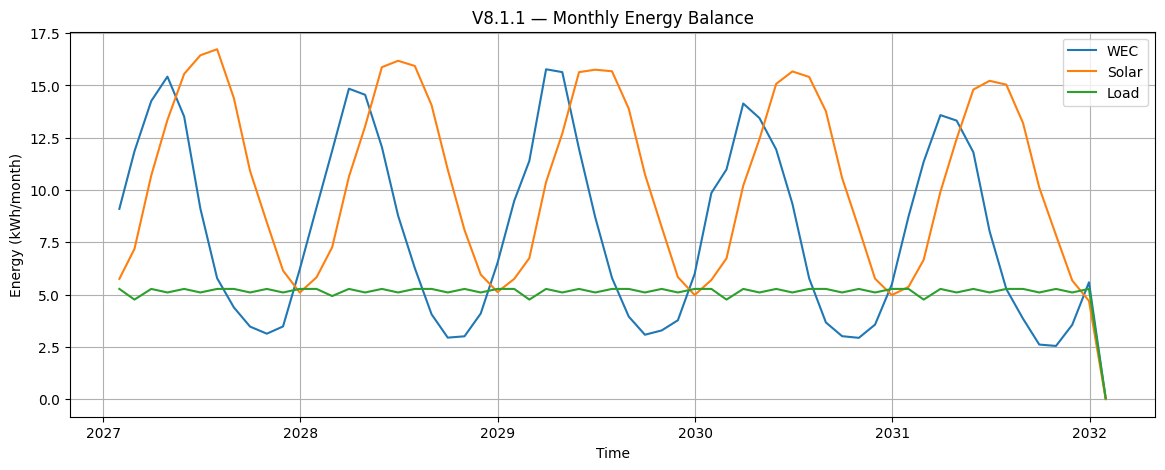


V8.1.1 outputs saved to:
/content/V8_1_1_outputs


In [2]:
# ============================================================
# SIH SMART BUOY — V8.1.1
# CORRECTED LOAD + EVENT-BASED COMMUNICATION ENGINE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. COMMUNICATION CONFIGURATION
# ============================================================

COMM_POWER_W = 15.0

COMM_EVENT_DURATION_H = 0.10

COMM_EVENTS_NORMAL_PER_DAY = 3

COMM_EVENTS_LOW_PER_DAY = 1

# Critical / Emergency / Reserve:
# communication OFF


# Energy per communication event

COMM_EVENT_ENERGY_Wh = (
    COMM_POWER_W
    * COMM_EVENT_DURATION_H
)

print(
    f"Communication event energy: "
    f"{COMM_EVENT_ENERGY_Wh:.2f} Wh/event"
)

print(
    f"Normal daily communication energy: "
    f"{COMM_EVENT_ENERGY_Wh * COMM_EVENTS_NORMAL_PER_DAY:.2f} Wh/day"
)


# ============================================================
# 2. BASE LOADS
# ============================================================

BASE_NORMAL = {
    "MCU": 1.5,
    "PowerManagement": 0.8,
    "DataLogger": 0.5,
    "Temperature": 0.2,
    "WaveSensor": 1.8,
    "GNSS": 1.5,
    "Status": 0.1,
    "NonEssential": 0.5
}

BASE_LOW = {
    "MCU": 1.2,
    "PowerManagement": 0.7,
    "DataLogger": 0.4,
    "Temperature": 0.2,
    "WaveSensor": 0.6,
    "GNSS": 0.8,
    "Status": 0.0,
    "NonEssential": 0.0
}

BASE_CRITICAL = {
    "MCU": 1.0,
    "PowerManagement": 0.7,
    "DataLogger": 0.3,
    "Temperature": 0.2,
    "WaveSensor": 0.0,
    "GNSS": 0.0,
    "Status": 0.0,
    "NonEssential": 0.0
}

BASE_EMERGENCY = {
    "MCU": 1.0,
    "PowerManagement": 0.7,
    "DataLogger": 0.3,
    "Temperature": 0.2
}

BASE_RESERVE = {
    "MCU": 0.8,
    "PowerManagement": 0.5,
    "Temperature": 0.2
}


def base_power(profile):

    return sum(profile.values())


BASE_LOADS = {

    "NORMAL":
        base_power(BASE_NORMAL),

    "LOW":
        base_power(BASE_LOW),

    "CRITICAL":
        base_power(BASE_CRITICAL),

    "EMERGENCY":
        base_power(BASE_EMERGENCY),

    "RESERVE":
        base_power(BASE_RESERVE)
}


print("\nBase loads:")

for mode, value in BASE_LOADS.items():

    print(
        f"{mode:10s}: "
        f"{value:.2f} W"
    )


# ============================================================
# 3. EVENT-BASED LOAD FUNCTION
# ============================================================

def communication_energy_for_hour(
    timestamp,
    mode
):

    hour = timestamp.hour

    minute = timestamp.minute

    # Convert time to fractional hour
    time_of_day = (
        hour
        + minute / 60
    )

    # Three normal events:
    # 08:00
    # 14:00
    # 20:00
    normal_events = [
        8.0,
        14.0,
        20.0
    ]

    # One reduced event in LOW mode
    low_events = [
        14.0
    ]

    if mode == "NORMAL":

        events = normal_events

    elif mode == "LOW":

        events = low_events

    else:

        events = []

    # Determine whether this hourly bin
    # contains a communication event.

    event_energy = 0.0

    for event_time in events:

        if (
            time_of_day
            <= event_time
            <
            time_of_day + 1.0
        ):

            event_energy += (
                COMM_EVENT_ENERGY_Wh
            )

    return event_energy


# ============================================================
# 4. LOAD ENERGY PER TIMESTEP
# ============================================================

def load_for_timestep(
    timestamp,
    mode,
    timestep_hours=1.0
):

    base = (
        BASE_LOADS[mode]
        * timestep_hours
    )

    communication = (
        communication_energy_for_hour(
            timestamp,
            mode
        )
    )

    return (
        base
        + communication
    )


# ============================================================
# 5. CORRECTED SIMULATION
# ============================================================

def run_v8_1_1(environment):

    df = environment.copy()

    if not isinstance(
        df.index,
        pd.DatetimeIndex
    ):

        if "Timestamp" in df.columns:

            df["Timestamp"] = pd.to_datetime(
                df["Timestamp"]
            )

            df = df.set_index(
                "Timestamp"
            )

        else:

            df.index = pd.to_datetime(
                df.index
            )

    df = df.sort_index()

    soc = CFG.initial_soc

    results = []

    reserve_events = 0

    was_reserve = False

    for timestamp, row in df.iterrows():

        elapsed_hours = (
            timestamp
            - df.index[0]
        ).total_seconds() / 3600

        year_fraction = (
            elapsed_hours
            / (365.25 * 24)
        )

        year = (
            int(year_fraction) + 1
        )

        year = min(
            year,
            CFG.years
        )

        Hs = float(
            row["Hs_m"]
        )

        Tp = float(
            row["Tp_s"]
        )

        irradiance = float(
            row[
                "Solar_Irradiance_Wm2"
            ]
        )

        # ----------------------------------------------------
        # MODE
        # ----------------------------------------------------

        mode = determine_mode(
            soc
        )

        if (
            mode == "RESERVE"
            and not was_reserve
        ):

            reserve_events += 1

        was_reserve = (
            mode == "RESERVE"
        )

        # ----------------------------------------------------
        # WEC
        # ----------------------------------------------------

        P_wec = total_wec_power(
            Hs,
            Tp,
            year_fraction
        )

        # ----------------------------------------------------
        # SOLAR
        # ----------------------------------------------------

        P_solar = solar_power(
            irradiance,
            year_fraction
        )

        E_wec = (
            P_wec
            * CFG.timestep_hours
        )

        E_solar = (
            P_solar
            * CFG.timestep_hours
        )

        # ----------------------------------------------------
        # LOAD
        # ----------------------------------------------------

        E_load = load_for_timestep(
            timestamp,
            mode,
            CFG.timestep_hours
        )

        P_load_equivalent = (
            E_load
            / CFG.timestep_hours
        )

        # ----------------------------------------------------
        # BATTERY
        # ----------------------------------------------------

        capacity = (
            battery_capacity_Wh(
                year_fraction
            )
        )

        battery_energy = (
            soc
            * capacity
        )

        generation = (
            E_wec
            + E_solar
        )

        net_energy = (
            generation
            - E_load
        )

        curtailed = 0.0

        unmet = 0.0

        battery_charge = 0.0

        battery_discharge = 0.0

        # ----------------------------------------------------
        # SURPLUS
        # ----------------------------------------------------

        if net_energy >= 0:

            charge_limit = (
                CFG.max_charge_W
                * CFG.timestep_hours
            )

            battery_charge = min(
                net_energy,
                charge_limit
            )

            new_energy = (
                battery_energy
                + battery_charge
            )

            if new_energy > capacity:

                curtailed = (
                    new_energy
                    - capacity
                )

                new_energy = capacity

            soc = (
                new_energy
                / capacity
            )

        # ----------------------------------------------------
        # DEFICIT
        # ----------------------------------------------------

        else:

            requested = (
                -net_energy
            )

            reserve_energy = (
                CFG.reserve_soc
                * capacity
            )

            available = max(
                0.0,
                battery_energy
                - reserve_energy
            )

            discharge_limit = (
                CFG.max_discharge_W
                * CFG.timestep_hours
            )

            battery_discharge = min(
                requested,
                available,
                discharge_limit
            )

            battery_energy -= (
                battery_discharge
            )

            unmet = (
                requested
                - battery_discharge
            )

            soc = (
                battery_energy
                / capacity
            )

            soc = max(
                CFG.reserve_soc,
                soc
            )

        # ----------------------------------------------------
        # COMMUNICATION FLAG
        # ----------------------------------------------------

        communication_energy = (
            communication_energy_for_hour(
                timestamp,
                mode
            )
        )

        # ----------------------------------------------------
        # STORE
        # ----------------------------------------------------

        results.append({

            "Timestamp": timestamp,

            "Year": year,

            "Hs_m": Hs,

            "Tp_s": Tp,

            "Mode": mode,

            "WEC_Power_W": P_wec,

            "Solar_Power_W": P_solar,

            "WEC_Energy_Wh": E_wec,

            "Solar_Energy_Wh": E_solar,

            "Base_Load_Wh":
                BASE_LOADS[mode]
                * CFG.timestep_hours,

            "Communication_Wh":
                communication_energy,

            "Load_Energy_Wh":
                E_load,

            "Battery_Capacity_Wh":
                capacity,

            "Battery_Charge_Wh":
                battery_charge,

            "Battery_Discharge_Wh":
                battery_discharge,

            "Curtailed_Wh":
                curtailed,

            "Unmet_Wh":
                unmet,

            "SOC":
                soc,

            "Storm":
                Hs >= CFG.storm_Hs_m
        })

    result = pd.DataFrame(
        results
    )

    result["SOC_pct"] = (
        result["SOC"] * 100
    )

    result.attrs[
        "reserve_events"
    ] = reserve_events

    return result


# ============================================================
# 6. YEARLY SUMMARY
# ============================================================

def yearly_summary_v811(
    result
):

    rows = []

    for year, group in result.groupby(
        "Year"
    ):

        total_hours = len(group)

        unmet_hours = (
            group["Unmet_Wh"] > 0
        ).sum()

        survival = (
            1
            -
            unmet_hours
            / total_hours
        ) * 100

        rows.append({

            "Year":
                year,

            "WEC_kWh":
                group[
                    "WEC_Energy_Wh"
                ].sum() / 1000,

            "Solar_kWh":
                group[
                    "Solar_Energy_Wh"
                ].sum() / 1000,

            "Generation_kWh":
                (
                    group[
                        "WEC_Energy_Wh"
                    ].sum()
                    +
                    group[
                        "Solar_Energy_Wh"
                    ].sum()
                ) / 1000,

            "Load_kWh":
                group[
                    "Load_Energy_Wh"
                ].sum() / 1000,

            "Communication_kWh":
                group[
                    "Communication_Wh"
                ].sum() / 1000,

            "Curtailed_kWh":
                group[
                    "Curtailed_Wh"
                ].sum() / 1000,

            "Unmet_kWh":
                group[
                    "Unmet_Wh"
                ].sum() / 1000,

            "Min_SOC_%":
                group[
                    "SOC_pct"
                ].min(),

            "Avg_SOC_%":
                group[
                    "SOC_pct"
                ].mean(),

            "Final_SOC_%":
                group[
                    "SOC_pct"
                ].iloc[-1],

            "Reserve_h":
                (
                    group["Mode"]
                    == "RESERVE"
                ).sum(),

            "Low_h":
                (
                    group["Mode"]
                    == "LOW"
                ).sum(),

            "Critical_h":
                (
                    group["Mode"]
                    == "CRITICAL"
                ).sum(),

            "Emergency_h":
                (
                    group["Mode"]
                    == "EMERGENCY"
                ).sum(),

            "Normal_h":
                (
                    group["Mode"]
                    == "NORMAL"
                ).sum(),

            "Storm_h":
                group["Storm"].sum(),

            "Load_survival_%":
                survival
        })

    return pd.DataFrame(
        rows
    )


# ============================================================
# 7. FULL RELIABILITY SUMMARY
# ============================================================

def reliability_v811(
    result
):

    total_hours = len(
        result
    )

    unmet_energy = (
        result[
            "Unmet_Wh"
        ].sum()
    )

    unmet_hours = (
        result[
            "Unmet_Wh"
        ] > 0
    ).sum()

    communication_energy = (
        result[
            "Communication_Wh"
        ].sum()
    )

    return {

        "Years":
            CFG.years,

        "Hours":
            total_hours,

        "WEC_kWh":
            result[
                "WEC_Energy_Wh"
            ].sum() / 1000,

        "Solar_kWh":
            result[
                "Solar_Energy_Wh"
            ].sum() / 1000,

        "Generation_kWh":
            (
                result[
                    "WEC_Energy_Wh"
                ].sum()
                +
                result[
                    "Solar_Energy_Wh"
                ].sum()
            ) / 1000,

        "Load_kWh":
            result[
                "Load_Energy_Wh"
            ].sum() / 1000,

        "Communication_kWh":
            communication_energy
            / 1000,

        "Curtailed_kWh":
            result[
                "Curtailed_Wh"
            ].sum() / 1000,

        "Unmet_kWh":
            unmet_energy
            / 1000,

        "Minimum_SOC_%":
            result[
                "SOC_pct"
            ].min(),

        "Average_SOC_%":
            result[
                "SOC_pct"
            ].mean(),

        "Final_SOC_%":
            result[
                "SOC_pct"
            ].iloc[-1],

        "Reserve_h":
            (
                result["Mode"]
                == "RESERVE"
            ).sum(),

        "Low_h":
            (
                result["Mode"]
                == "LOW"
            ).sum(),

        "Critical_h":
            (
                result["Mode"]
                == "CRITICAL"
            ).sum(),

        "Emergency_h":
            (
                result["Mode"]
                == "EMERGENCY"
            ).sum(),

        "Storm_h":
            result["Storm"].sum(),

        "Unmet_hours":
            unmet_hours,

        "Load_survival_%":
            (
                1
                -
                unmet_hours
                / total_hours
            ) * 100
    }


# ============================================================
# 8. RUN V8.1.1
# ============================================================

print(
    "\n===================================="
)

print(
    "RUNNING V8.1.1"
)

print(
    "===================================="
)


result_811 = run_v8_1_1(
    environment
)


# ============================================================
# 9. REPORT
# ============================================================

summary_811 = reliability_v811(
    result_811
)

print(
    "\n=============================="
)

print(
    "V8.1.1 FIVE-YEAR RESULT"
)

print(
    "=============================="
)

for key, value in summary_811.items():

    if isinstance(
        value,
        (float, np.floating)
    ):

        print(
            f"{key:25s}: "
            f"{value:.3f}"
        )

    else:

        print(
            f"{key:25s}: "
            f"{value}"
        )


# ============================================================
# 10. YEAR-BY-YEAR
# ============================================================

annual_811 = yearly_summary_v811(
    result_811
)

print(
    "\n=============================="
)

print(
    "YEAR-BY-YEAR"
)

print(
    "=============================="
)

display(
    annual_811.round(3)
)


# ============================================================
# 11. DAILY ENERGY DIAGNOSTIC
# ============================================================

daily = (
    result_811
    .set_index("Timestamp")
    .resample("D")
    .agg({

        "WEC_Energy_Wh": "sum",

        "Solar_Energy_Wh": "sum",

        "Load_Energy_Wh": "sum",

        "Communication_Wh": "sum",

        "Curtailed_Wh": "sum",

        "Unmet_Wh": "sum",

        "SOC_pct": "min"
    })
)

daily.columns = [

    "WEC_Wh_day",
    "Solar_Wh_day",
    "Load_Wh_day",
    "Communication_Wh_day",
    "Curtailed_Wh_day",
    "Unmet_Wh_day",
    "Minimum_SOC_pct_day"
]

print(
    "\nDaily energy diagnostic:"
)

display(
    daily.head(10).round(3)
)


# ============================================================
# 12. COMMUNICATION VALIDATION
# ============================================================

normal_comm = (
    result_811.loc[
        result_811["Mode"] == "NORMAL",
        "Communication_Wh"
    ].sum()
)

print(
    "\nCommunication energy:"
)

print(
    f"5-year total: "
    f"{normal_comm / 1000:.3f} kWh"
)

print(
    f"Expected normal-day value: "
    f"{COMM_EVENT_ENERGY_Wh * COMM_EVENTS_NORMAL_PER_DAY:.2f} Wh/day"
)


# ============================================================
# 13. PLOTS
# ============================================================

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    result_811["Timestamp"],
    result_811["SOC_pct"]
)

plt.axhline(
    10,
    linestyle="--",
    label="10% protected reserve"
)

plt.axhline(
    35,
    linestyle="--",
    label="Normal threshold"
)

plt.xlabel(
    "Time"
)

plt.ylabel(
    "SOC (%)"
)

plt.title(
    "V8.1.1 — Battery SOC"
)

plt.legend()

plt.grid(True)

plt.show()


# ------------------------------------------------------------

monthly = (
    result_811
    .set_index("Timestamp")
    .resample("ME")
    .agg({

        "WEC_Energy_Wh": "sum",

        "Solar_Energy_Wh": "sum",

        "Load_Energy_Wh": "sum"
    })
) / 1000


plt.figure(
    figsize=(14, 5)
)

plt.plot(
    monthly.index,
    monthly["WEC_Energy_Wh"],
    label="WEC"
)

plt.plot(
    monthly.index,
    monthly["Solar_Energy_Wh"],
    label="Solar"
)

plt.plot(
    monthly.index,
    monthly["Load_Energy_Wh"],
    label="Load"
)

plt.xlabel(
    "Time"
)

plt.ylabel(
    "Energy (kWh/month)"
)

plt.title(
    "V8.1.1 — Monthly Energy Balance"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 14. EXPORT
# ============================================================

output_dir = Path(
    "V8_1_1_outputs"
)

output_dir.mkdir(
    exist_ok=True
)

result_811.to_csv(
    output_dir
    / "V8_1_1_hourly_results.csv",
    index=False
)

annual_811.to_csv(
    output_dir
    / "V8_1_1_yearly_summary.csv",
    index=False
)

daily.to_csv(
    output_dir
    / "V8_1_1_daily_diagnostics.csv"
)

pd.DataFrame(
    [summary_811]
).to_csv(
    output_dir
    / "V8_1_1_reliability_summary.csv",
    index=False
)

print(
    "\nV8.1.1 outputs saved to:"
)

print(
    output_dir.resolve()
)

In [3]:
# ============================================================
# SIH SMART BUOY — V8.2
# REAL SOUTHERN OCEAN CLIMATE ENGINE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 1. FILE CONFIGURATION
# ============================================================

REAL_DATA_FILE = "southern_ocean_era5.csv"

OUTPUT_DIR = Path("V8_2_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


# ============================================================
# 2. LOAD REAL ENVIRONMENT
# ============================================================

def load_real_environment(filename):

    df = pd.read_csv(filename)

    required = [
        "Timestamp",
        "Hs_m",
        "Tp_s",
        "Wave_direction_deg",
        "Solar_Irradiance_Wm2",
        "Air_temperature_C"
    ]

    missing = [
        c for c in required
        if c not in df.columns
    ]

    if missing:

        raise ValueError(
            "Missing columns: "
            + str(missing)
        )

    df["Timestamp"] = pd.to_datetime(
        df["Timestamp"],
        utc=True
    )

    df = (
        df
        .sort_values("Timestamp")
        .drop_duplicates(
            "Timestamp"
        )
        .set_index("Timestamp")
    )

    return df


# ============================================================
# 3. QUALITY CONTROL
# ============================================================

def quality_control(df):

    df = df.copy()

    # Physical limits

    df.loc[
        (df["Hs_m"] < 0) |
        (df["Hs_m"] > 20),
        "Hs_m"
    ] = np.nan

    df.loc[
        (df["Tp_s"] < 1) |
        (df["Tp_s"] > 30),
        "Tp_s"
    ] = np.nan

    df.loc[
        (df["Wave_direction_deg"] < 0) |
        (df["Wave_direction_deg"] >= 360),
        "Wave_direction_deg"
    ] = np.nan

    df.loc[
        (df["Solar_Irradiance_Wm2"] < 0),
        "Solar_Irradiance_Wm2"
    ] = np.nan

    df.loc[
        (df["Solar_Irradiance_Wm2"] > 1400),
        "Solar_Irradiance_Wm2"
    ] = np.nan

    # Reindex to exact hourly grid

    full_index = pd.date_range(
        df.index.min(),
        df.index.max(),
        freq="1h",
        tz="UTC"
    )

    df = df.reindex(
        full_index
    )

    # Small gaps only

    for col in [
        "Hs_m",
        "Tp_s",
        "Wave_direction_deg",
        "Solar_Irradiance_Wm2",
        "Air_temperature_C"
    ]:

        df[col] = (
            df[col]
            .interpolate(
                limit=3
            )
        )

    # Remaining missing values

    df["Data_Gap"] = (
        df[
            [
                "Hs_m",
                "Tp_s",
                "Solar_Irradiance_Wm2"
            ]
        ]
        .isna()
        .any(axis=1)
    )

    return df


# ============================================================
# 4. REAL WAVE STATISTICS
# ============================================================

def climate_statistics(df):

    wave = df["Hs_m"].dropna()

    stats = {

        "records":
            len(df),

        "coverage_%":
            100 *
            (
                1
                -
                df["Data_Gap"].mean()
            ),

        "Hs_mean_m":
            wave.mean(),

        "Hs_median_m":
            wave.median(),

        "Hs_max_m":
            wave.max(),

        "Hs_P90_m":
            wave.quantile(0.90),

        "Hs_P95_m":
            wave.quantile(0.95),

        "Hs_P99_m":
            wave.quantile(0.99),

        "Tp_mean_s":
            df["Tp_s"].mean(),

        "Tp_median_s":
            df["Tp_s"].median(),

        "Solar_mean_Wm2":
            df[
                "Solar_Irradiance_Wm2"
            ].mean()
    }

    return stats


# ============================================================
# 5. PROVISIONAL Hs/Tp WEC MODEL
# ============================================================

# Current V7 provisional calibration

Hs_table = np.array([
    0.25,
    0.50,
    1.00,
    1.50,
    2.00,
    2.50,
    3.00
])

Torque_table = np.array([
    0.30,
    1.20,
    4.80,
    10.80,
    19.20,
    30.00,
    43.20
])

RPM_table = np.array([
    1.82,
    3.43,
    6.36,
    8.75,
    11.53,
    13.90,
    16.14
])


def provisional_torque(
    Hs,
    Tp
):

    if Hs < 0.25:
        return 0.0

    if Hs >= 3.0:
        return 0.0

    torque = np.interp(
        Hs,
        Hs_table,
        Torque_table
    )

    # Temporary period correction.
    #
    # IMPORTANT:
    # This is NOT experimental calibration.
    # It only prevents V8.2 from ignoring Tp.

    Tp_reference = 8.0

    period_factor = (
        Tp / Tp_reference
    ) ** 0.35

    period_factor = np.clip(
        period_factor,
        0.75,
        1.25
    )

    return (
        torque
        * period_factor
    )


def provisional_rpm(
    Hs,
    Tp
):

    if Hs < 0.25:
        return 0.0

    if Hs >= 3.0:
        return 0.0

    rpm = np.interp(
        Hs,
        Hs_table,
        RPM_table
    )

    Tp_reference = 8.0

    period_factor = (
        Tp_reference / Tp
    ) ** 0.20

    period_factor = np.clip(
        period_factor,
        0.85,
        1.15
    )

    return (
        rpm
        * period_factor
    )


# ============================================================
# 6. GENERATOR EFFICIENCY
# ============================================================

GEN_RPM = np.array([
    0,
    30,
    50,
    75,
    100,
    125,
    150,
    175,
    200,
    250,
    300,
    400,
    500,
    600
])

GEN_EFF = np.array([
    0,
    0.02,
    0.08,
    0.22,
    0.38,
    0.50,
    0.55,
    0.58,
    0.60,
    0.63,
    0.65,
    0.62,
    0.55,
    0.45
])


def generator_efficiency(
    rpm
):

    return np.interp(
        rpm,
        GEN_RPM,
        GEN_EFF
    )


# ============================================================
# 7. GEARBOX
# ============================================================

GEAR_RPM = np.array([
    0,
    50,
    100,
    150,
    200,
    300,
    400,
    500,
    600
])

GEAR_EFF = np.array([
    0,
    0.88,
    0.90,
    0.90,
    0.90,
    0.90,
    0.89,
    0.88,
    0.86
])


def gearbox_efficiency(
    generator_rpm
):

    return np.interp(
        generator_rpm,
        GEAR_RPM,
        GEAR_EFF
    )


# ============================================================
# 8. REAL WEC POWER
# ============================================================

def real_wec_power(
    Hs,
    Tp,
    year_fraction
):

    torque = provisional_torque(
        Hs,
        Tp
    )

    arm_rpm = provisional_rpm(
        Hs,
        Tp
    )

    if torque <= 0:
        return 0.0

    if arm_rpm <= 0:
        return 0.0

    # Storm protection

    if Hs >= CFG.storm_Hs_m:
        return 0.0

    arm_omega = (
        2
        * np.pi
        * arm_rpm
        / 60
    )

    mechanical_arm_power = (
        torque
        * arm_omega
    )

    generator_rpm = (
        arm_rpm
        * CFG.gearbox_ratio
    )

    eta_gear = (
        gearbox_efficiency(
            generator_rpm
        )
    )

    eta_generator = (
        generator_efficiency(
            generator_rpm
        )
    )

    # Degradation

    wec_deg = (
        (1 - CFG.wec_deg_per_year)
        ** year_fraction
    )

    gen_deg = (
        (1 - CFG.generator_deg_per_year)
        ** year_fraction
    )

    P_one_arm = (
        mechanical_arm_power
        * eta_gear
        * eta_generator
        * CFG.controller_efficiency
        * wec_deg
        * gen_deg
    )

    P_total = (
        CFG.n_arms
        * P_one_arm
    )

    return min(
        P_total,
        CFG.n_arms * 75.0
    )


# ============================================================
# 9. REAL SOLAR POWER
# ============================================================

def real_solar_power(
    irradiance,
    year_fraction
):

    degradation = (
        (1 - CFG.solar_deg_per_year)
        ** year_fraction
    )

    power = (
        CFG.solar_rated_W
        *
        irradiance
        /
        CFG.solar_reference_irradiance
        *
        degradation
    )

    return np.clip(
        power,
        0,
        CFG.solar_rated_W
        * degradation
    )


# ============================================================
# 10. TEMPERATURE DERATING
# ============================================================

def temperature_factor(
    temperature_C
):

    # Provisional polar derating.
    # Replace with battery manufacturer
    # test data before final validation.

    if temperature_C >= 0:

        return 1.0

    elif temperature_C >= -10:

        return 0.95

    elif temperature_C >= -20:

        return 0.90

    elif temperature_C >= -30:

        return 0.80

    else:

        return 0.70


# ============================================================
# 11. LOAD MODEL
# ============================================================

def communication_energy(
    timestamp,
    mode
):

    if mode == "NORMAL":

        events = [8, 14, 20]

    elif mode == "LOW":

        events = [14]

    else:

        events = []

    energy = 0.0

    for event in events:

        if timestamp.hour == event:

            energy += 1.5

    return energy


def load_energy(
    timestamp,
    mode
):

    base = {
        "NORMAL": 6.9,
        "LOW": 3.9,
        "CRITICAL": 2.2,
        "EMERGENCY": 2.2,
        "RESERVE": 1.5
    }[mode]

    return (
        base
        +
        communication_energy(
            timestamp,
            mode
        )
    )


# ============================================================
# 12. BATTERY CAPACITY
# ============================================================

def battery_capacity(
    year_fraction
):

    return (
        CFG.battery_nominal_Wh
        *
        (1 - CFG.battery_deg_per_year)
        ** year_fraction
    )


# ============================================================
# 13. RUN V8.2
# ============================================================

def run_v82(
    climate
):

    df = climate.copy()

    soc = CFG.initial_soc

    records = []

    start = df.index[0]

    for timestamp, row in df.iterrows():

        elapsed_hours = (
            timestamp
            - start
        ).total_seconds() / 3600

        year_fraction = (
            elapsed_hours
            / (365.25 * 24)
        )

        year = (
            int(year_fraction) + 1
        )

        year = min(
            year,
            CFG.years
        )

        Hs = row["Hs_m"]

        Tp = row["Tp_s"]

        solar_irr = (
            row[
                "Solar_Irradiance_Wm2"
            ]
        )

        temp = (
            row[
                "Air_temperature_C"
            ]
        )

        # ----------------------------------------
        # MODE
        # ----------------------------------------

        mode = determine_mode(
            soc
        )

        # ----------------------------------------
        # TEMPERATURE
        # ----------------------------------------

        temp_factor = (
            temperature_factor(
                temp
            )
        )

        # ----------------------------------------
        # GENERATION
        # ----------------------------------------

        P_wec = real_wec_power(
            Hs,
            Tp,
            year_fraction
        )

        P_solar = real_solar_power(
            solar_irr,
            year_fraction
        )

        generation = (
            P_wec
            +
            P_solar
        ) * CFG.timestep_hours

        # ----------------------------------------
        # LOAD
        # ----------------------------------------

        load = load_energy(
            timestamp,
            mode
        )

        # ----------------------------------------
        # BATTERY
        # ----------------------------------------

        capacity = (
            battery_capacity(
                year_fraction
            )
        )

        capacity *= temp_factor

        battery_energy = (
            soc
            * capacity
        )

        net = (
            generation
            - load
        )

        charge = 0.0
        discharge = 0.0
        curtailed = 0.0
        unmet = 0.0

        if net >= 0:

            charge_limit = (
                CFG.max_charge_W
                * CFG.timestep_hours
            )

            charge = min(
                net,
                charge_limit
            )

            new_energy = (
                battery_energy
                + charge
            )

            if new_energy > capacity:

                curtailed = (
                    new_energy
                    - capacity
                )

                new_energy = capacity

            soc = (
                new_energy
                / capacity
            )

        else:

            required = -net

            reserve = (
                CFG.reserve_soc
                * capacity
            )

            available = max(
                0,
                battery_energy
                - reserve
            )

            discharge_limit = (
                CFG.max_discharge_W
                * CFG.timestep_hours
            )

            discharge = min(
                required,
                available,
                discharge_limit
            )

            battery_energy -= (
                discharge
            )

            unmet = (
                required
                - discharge
            )

            soc = (
                battery_energy
                / capacity
            )

            soc = max(
                CFG.reserve_soc,
                soc
            )

        records.append({

            "Timestamp":
                timestamp,

            "Year":
                year,

            "Hs_m":
                Hs,

            "Tp_s":
                Tp,

            "Wave_direction_deg":
                row[
                    "Wave_direction_deg"
                ],

            "Solar_Irradiance_Wm2":
                solar_irr,

            "Air_temperature_C":
                temp,

            "Temperature_Factor":
                temp_factor,

            "Mode":
                mode,

            "WEC_Wh":
                P_wec,

            "Solar_Wh":
                P_solar,

            "Load_Wh":
                load,

            "Charge_Wh":
                charge,

            "Discharge_Wh":
                discharge,

            "Curtailed_Wh":
                curtailed,

            "Unmet_Wh":
                unmet,

            "SOC_pct":
                soc * 100,

            "Storm":
                Hs >= CFG.storm_Hs_m
        })

    return pd.DataFrame(
        records
    )


# ============================================================
# 14. LOAD DATA
# ============================================================

print(
    "Loading real Southern Ocean data..."
)

climate = load_real_environment(
    REAL_DATA_FILE
)

climate = quality_control(
    climate
)

print(
    "\nClimate dataset:"
)

print(
    climate.head()
)


# ============================================================
# 15. CLIMATE STATISTICS
# ============================================================

stats = climate_statistics(
    climate
)

print(
    "\n=============================="
)

print(
    "REAL CLIMATE STATISTICS"
)

print(
    "=============================="
)

for key, value in stats.items():

    print(
        f"{key:25s}: "
        f"{value:.3f}"
    )


# ============================================================
# 16. RUN
# ============================================================

print(
    "\n=============================="
)

print(
    "RUNNING V8.2"
)

print(
    "=============================="
)

v82 = run_v82(
    climate
)


# ============================================================
# 17. SUMMARY
# ============================================================

summary = {

    "WEC_kWh":
        v82["WEC_Wh"].sum()
        / 1000,

    "Solar_kWh":
        v82["Solar_Wh"].sum()
        / 1000,

    "Generation_kWh":
        (
            v82["WEC_Wh"].sum()
            +
            v82["Solar_Wh"].sum()
        ) / 1000,

    "Load_kWh":
        v82["Load_Wh"].sum()
        / 1000,

    "Curtailed_kWh":
        v82["Curtailed_Wh"].sum()
        / 1000,

    "Unmet_kWh":
        v82["Unmet_Wh"].sum()
        / 1000,

    "Minimum_SOC_%":
        v82["SOC_pct"].min(),

    "Average_SOC_%":
        v82["SOC_pct"].mean(),

    "Final_SOC_%":
        v82["SOC_pct"].iloc[-1],

    "Reserve_h":
        (
            v82["Mode"]
            == "RESERVE"
        ).sum(),

    "Low_h":
        (
            v82["Mode"]
            == "LOW"
        ).sum(),

    "Critical_h":
        (
            v82["Mode"]
            == "CRITICAL"
        ).sum(),

    "Emergency_h":
        (
            v82["Mode"]
            == "EMERGENCY"
        ).sum(),

    "Storm_h":
        v82["Storm"].sum(),

    "Unmet_hours":
        (
            v82["Unmet_Wh"]
            > 0
        ).sum()
}


print(
    "\n=============================="
)

print(
    "V8.2 RESULT"
)

print(
    "=============================="
)

for key, value in summary.items():

    print(
        f"{key:25s}: "
        f"{value:.3f}"
    )


# ============================================================
# 18. YEARLY SUMMARY
# ============================================================

yearly = (
    v82
    .groupby("Year")
    .agg({

        "WEC_Wh": "sum",

        "Solar_Wh": "sum",

        "Load_Wh": "sum",

        "Curtailed_Wh": "sum",

        "Unmet_Wh": "sum",

        "SOC_pct": [
            "min",
            "mean",
            "last"
        ],

        "Storm": "sum"
    })
)

yearly.columns = [

    "WEC_kWh",
    "Solar_kWh",
    "Load_kWh",
    "Curtailed_kWh",
    "Unmet_kWh",
    "Min_SOC_pct",
    "Avg_SOC_pct",
    "Final_SOC_pct",
    "Storm_h"
]

yearly[
    [
        "WEC_kWh",
        "Solar_kWh",
        "Load_kWh",
        "Curtailed_kWh",
        "Unmet_kWh"
    ]
] /= 1000

print(
    "\n=============================="
)

print(
    "YEARLY V8.2 RESULT"
)

print(
    "=============================="
)

display(
    yearly.round(3)
)


# ============================================================
# 19. Hs DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.hist(
    climate["Hs_m"].dropna(),
    bins=40
)

plt.xlabel(
    "Significant Wave Height Hs (m)"
)

plt.ylabel(
    "Hours"
)

plt.title(
    "Real Southern Ocean Wave Climate"
)

plt.grid(True)

plt.show()


# ============================================================
# 20. SOC
# ============================================================

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    v82["Timestamp"],
    v82["SOC_pct"]
)

plt.axhline(
    10,
    linestyle="--",
    label="Protected reserve"
)

plt.axhline(
    35,
    linestyle="--",
    label="Normal threshold"
)

plt.xlabel(
    "Time"
)

plt.ylabel(
    "SOC (%)"
)

plt.title(
    "V8.2 — Real Climate Battery SOC"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 21. WAVE + WEC POWER
# ============================================================

fig, ax1 = plt.subplots(
    figsize=(14, 5)
)

ax1.plot(
    v82["Timestamp"],
    v82["Hs_m"]
)

ax1.set_xlabel(
    "Time"
)

ax1.set_ylabel(
    "Hs (m)"
)

ax2 = ax1.twinx()

ax2.plot(
    v82["Timestamp"],
    v82["WEC_Wh"]
)

ax2.set_ylabel(
    "WEC Power (W)"
)

plt.title(
    "V8.2 — Real Waves vs WEC Output"
)

plt.show()


# ============================================================
# 22. EXPORT
# ============================================================

v82.to_csv(
    OUTPUT_DIR
    / "V8_2_hourly_results.csv",
    index=False
)

yearly.to_csv(
    OUTPUT_DIR
    / "V8_2_yearly_summary.csv"
)

pd.DataFrame(
    [summary]
).to_csv(
    OUTPUT_DIR
    / "V8_2_reliability_summary.csv",
    index=False
)

pd.DataFrame(
    [stats]
).to_csv(
    OUTPUT_DIR
    / "V8_2_climate_statistics.csv",
    index=False
)

print(
    "\nV8.2 files saved to:"
)

print(
    OUTPUT_DIR.resolve()
)

Loading real Southern Ocean data...


FileNotFoundError: [Errno 2] No such file or directory: 'southern_ocean_era5.csv'